# Segmentación de clientes bancarios por preferencias de consumo

**Autora:** Eliana Salazar Laborí · **Herramientas:** Python (Pandas, Scikit-learn, Matplotlib, Seaborn)

**Origen:** caso desarrollado en el Programa de Especialización Analítica – Data Science Fundamentals (DMC, 2020). Esta versión revisa y corrige el análisis original.

## Resumen ejecutivo

- **Datos:** 339,476 registros de consumo con tarjeta de 40,000 clientes en 12 meses (nov. 2016 – oct. 2017), en 21 rubros comerciales.
- **Enfoque:** se segmentó a los 21,905 clientes con 3 o más meses de consumo (55% de los clientes y 91% de las transacciones) según la **proporción** de sus transacciones en cada rubro, con K-Means.
- **Resultado:** 6 segmentos estables. Cinco tienen un rubro dominante, que concentra entre 48% y 75% de sus transacciones: *Restaurantes y bares* (23%), *Supermercado* (22%), *Salud* (9%), *Vehículos y repuestos* (8%) y *Entretenimiento* (5%). El sexto, *Diversificado* (33%), reparte su consumo entre muchos rubros y tiene el ticket promedio más alto.
- **Uso:** cada segmento sugiere una oferta distinta, en lugar de enviar el mismo descuento a todos. Los 18,083 clientes ocasionales (1–2 meses de consumo) requieren campañas de activación, no ofertas por rubro.

## 1. Problema de negocio

Los bancos envían ofertas y descuentos a sus clientes en una competencia constante por incentivar el consumo con tarjeta. Cada descuento tiene un costo para el banco, se use o no. Enviar la misma oferta a todos es ineficiente.

**Pregunta:** ¿qué grupos de clientes existen según **en qué rubros** concentran sus compras con tarjeta de crédito y débito, y qué oferta tiene sentido para cada grupo?

**Enfoque:** segmentar a los clientes por la **composición** de su consumo (qué proporción de sus transacciones va a cada rubro), no por su volumen. Así un cliente que compra poco y uno que compra mucho en supermercados quedan en el mismo grupo de preferencia.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 2. Datos

Base de transacciones con tarjeta de crédito y débito proporcionada por el programa: un registro por cliente, mes y rubro, con el número de transacciones (`trx`) y el monto (`monto`), más variables demográficas en rangos.

> El archivo no se publica en el repositorio porque es material del programa. Para reproducir el análisis, colócalo en `data/02dataBaseConsumo.txt`.

In [2]:
df = pd.read_csv("data/02dataBaseConsumo.txt", sep="|", encoding="latin-1", dtype={"cliente": str})
print(f"Registros: {len(df):,} | Clientes: {df['cliente'].nunique():,} | Meses: {df['codmes'].min()} a {df['codmes'].max()} ({df['codmes'].nunique()})")
df.head()

Registros: 339,476 | Clientes: 40,000 | Meses: 201611 a 201710 (12)


,codmes,cliente,edad,ingreso,sexo,flgLimaProv,flgAfBxi,grupoGiro,monto,trx
0,201611,00032572,[1. <=25],[2. <=1500],F,1.0,1.0,restbar,12,1
1,201611,00029843,[1. <=25],[3. <=2500],F,0.0,1.0,prodlocal,22,1
2,201611,00030033,[2. <=30],[2. <=1500],F,0.0,1.0,restbar,10,1
3,201612,00003847,[7. > 55],[3. <=2500],M,1.0,0.0,restbar,350,4
4,201611,00033131,[1. <=25],[2. <=1500],F,1.0,1.0,restbar,65,2


### 2.1 Calidad de datos

In [3]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
})
calidad

,nulos,% nulos,valores únicos
codmes,0,0.0,12
cliente,0,0.0,40000
edad,12999,3.8,7
ingreso,31328,9.2,8
sexo,11755,3.5,2
flgLimaProv,11751,3.5,2
flgAfBxi,11751,3.5,2
grupoGiro,0,0.0,22
monto,0,0.0,4366
trx,0,0.0,57


In [4]:
# Rubros: hay un nombre con caracteres corruptos en el archivo de origen y un rubro sin identificar ("**")
print(df["grupoGiro"].value_counts().tail(8))

grupoGiro
belleza         4564
prodelectro     4432
artcultura      2914
alqbienes       2692
profdiverso     2136
hogaroficina    1378
**               228
informatica       86
Name: count, dtype: int64


In [5]:
df["grupoGiro"] = df["grupoGiro"].replace({"enseï¿½anza": "ensenanza"})

sin_rubro = df["grupoGiro"].eq("**")
print(f"Registros sin rubro identificado: {sin_rubro.sum():,} ({sin_rubro.mean():.2%}) -> se excluyen")
df = df[~sin_rubro].copy()

rubros = sorted(df["grupoGiro"].unique())
print(f"Rubros analizados: {len(rubros)}")

Registros sin rubro identificado: 228 (0.07%) -> se excluyen
Rubros analizados: 21


**Hallazgos de calidad:**

- Las variables de rubro, monto y transacciones no tienen nulos.
- Las demográficas (edad, ingreso, sexo, ubicación) tienen entre 3% y 9% de nulos. **No se usan para formar los segmentos**, solo para describirlos después, así que no se descarta a ningún cliente por tenerlas vacías.
- Se corrige el nombre del rubro *enseñanza*, que viene con caracteres corruptos, y se excluye el rubro `**` (sin identificar, 0.07% de los registros).

## 3. Preparación: de transacciones a perfil de cliente

### 3.1 ¿A qué clientes segmentar?

Para medir preferencias se necesita historia suficiente. Un cliente con una sola transacción en el año tiene el 100% de su consumo en un rubro, y eso no es una preferencia sino una compra aislada.

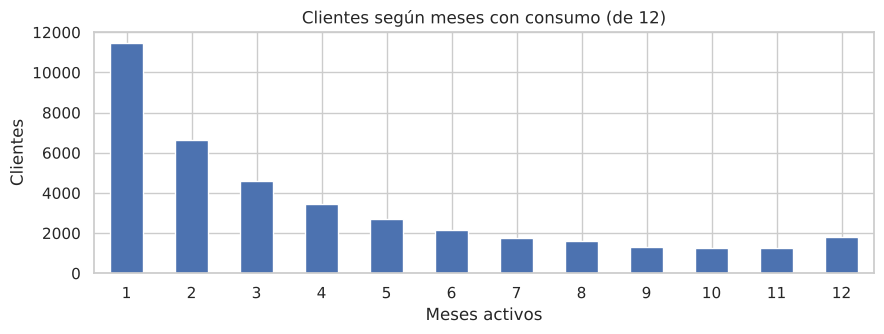

meses_activos
1 mes        1.0
2 meses      3.0
3+ meses    14.0
Name: mediana de transacciones al año, dtype: float64


In [6]:
clientes = df.groupby("cliente").agg(
    meses_activos=("codmes", "nunique"),
    trx_total=("trx", "sum"),
    monto_total=("monto", "sum"),
)

dist_meses = clientes["meses_activos"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.5))
dist_meses.plot.bar(ax=ax, color="#4C72B0")
ax.set(title="Clientes según meses con consumo (de 12)", xlabel="Meses activos", ylabel="Clientes")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(clientes.groupby(clientes["meses_activos"].clip(upper=3))["trx_total"].median()
      .rename(index={1: "1 mes", 2: "2 meses", 3: "3+ meses"}).rename("mediana de transacciones al año"))

In [7]:
MIN_MESES = 3
base = clientes[clientes["meses_activos"] >= MIN_MESES]
ocasionales = clientes[clientes["meses_activos"] < MIN_MESES]

print(f"Clientes con {MIN_MESES}+ meses activos (se segmentan): {len(base):,} ({len(base)/len(clientes):.1%})")
print(f"Clientes ocasionales, 1-2 meses (grupo aparte):    {len(ocasionales):,} ({len(ocasionales)/len(clientes):.1%})")
print(f"Participación de los clientes segmentados en las transacciones: {base['trx_total'].sum()/clientes['trx_total'].sum():.1%}")

Clientes con 3+ meses activos (se segmentan): 21,905 (54.8%)
Clientes ocasionales, 1-2 meses (grupo aparte):    18,083 (45.2%)
Participación de los clientes segmentados en las transacciones: 90.8%


**Decisión:** se segmenta a los clientes con **3 o más meses de consumo**. Los clientes con 1 o 2 meses se tratan como un grupo aparte, *ocasionales*, porque su objetivo comercial es distinto: activarlos, no ofrecerles un rubro.

A diferencia de la versión original, **no se excluye a los clientes con 11 y 12 meses de actividad**, que son los más leales y los de mayor valor para una campaña.

### 3.2 Variables: proporción de transacciones por rubro

Para cada cliente se calcula qué porcentaje de sus transacciones del año fue a cada rubro. Las proporciones suman 1 por cliente, están acotadas entre 0 y 1 y ya están en la misma escala, por lo que **no requieren estandarización ni eliminación de outliers**: un cliente de alto volumen no distorsiona el modelo, simplemente tiene un perfil más preciso.

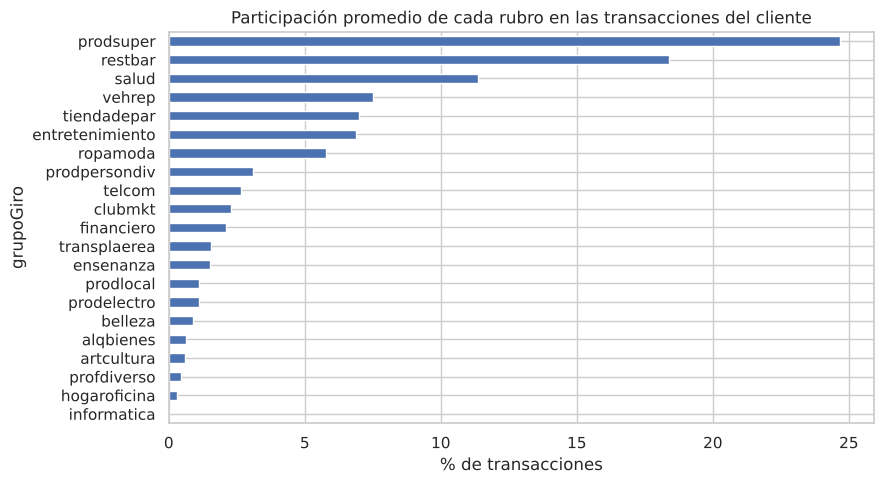

In [8]:
trx_rubro = df.pivot_table(index="cliente", columns="grupoGiro", values="trx", aggfunc="sum", fill_value=0)
X_conteo = trx_rubro.loc[base.index, rubros]
X = X_conteo.div(X_conteo.sum(axis=1), axis=0)

perfil_global = X.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
(perfil_global * 100).plot.barh(ax=ax, color="#4C72B0")
ax.invert_yaxis()
ax.set(title="Participación promedio de cada rubro en las transacciones del cliente", xlabel="% de transacciones")
plt.tight_layout(); plt.show()

Supermercados, restaurantes y salud concentran más de la mitad de las transacciones del cliente promedio. Los rubros pequeños (informática, hogar y oficina, servicios profesionales) pesan menos de 1% cada uno.

## 4. Modelo: K-Means

### 4.1 Elección del número de segmentos

Se evalúan de 2 a 10 segmentos con tres criterios: inercia (método del codo), coeficiente de silueta y tamaño del segmento más grande (un segmento que concentra a casi todos no sirve para diferenciar ofertas).

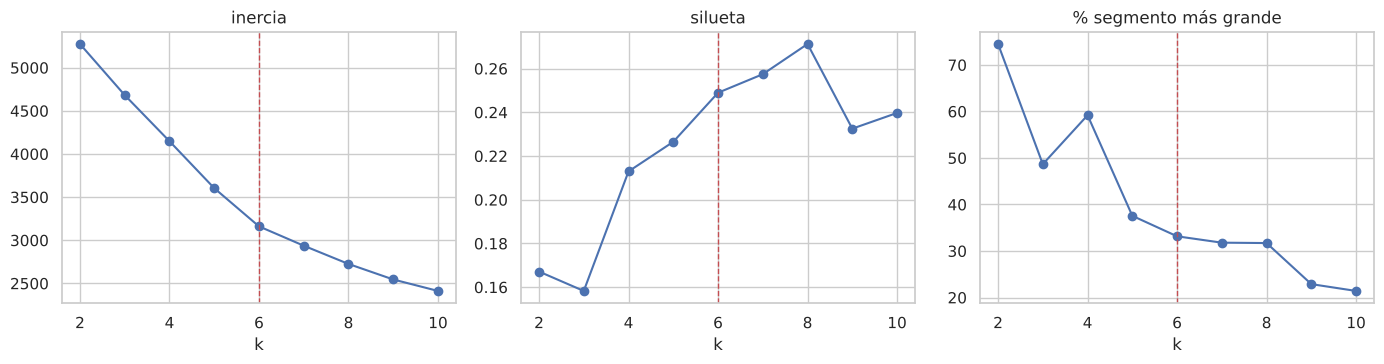

,inercia,silueta,% segmento más grande
k,,,
2,5274.461,0.167,74.494
3,4681.990,0.158,48.665
4,4147.885,0.213,59.187
5,3603.746,0.227,37.562
6,3160.808,0.249,33.161
7,2936.844,0.257,31.792
8,2725.293,0.271,31.710
9,2545.392,0.233,22.881
10,2412.401,0.240,21.415


In [9]:
resultados = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    resultados.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(X, km.labels_, sample_size=8000, random_state=SEMILLA),
        "% segmento más grande": np.bincount(km.labels_).max() / len(X) * 100,
    })
resultados = pd.DataFrame(resultados).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, resultados.columns):
    resultados[col].plot(ax=ax, marker="o", color="#4C72B0")
    ax.axvline(6, color="#C44E52", ls="--", lw=1)
    ax.set(title=col, xlabel="k")
plt.tight_layout(); plt.show()
resultados.round(3)

In [10]:
# Estabilidad: ¿se obtienen los mismos segmentos con distintas inicializaciones?
for k in (5, 6, 7):
    etiquetas = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X) for s in range(5)]
    ari = [adjusted_rand_score(etiquetas[0], e) for e in etiquetas[1:]]
    print(f"k={k}: índice de Rand ajustado entre semillas = {min(ari):.3f} (mínimo) a {max(ari):.3f} (máximo)")

k=5: índice de Rand ajustado entre semillas = 0.491 (mínimo) a 0.999 (máximo)


k=6: índice de Rand ajustado entre semillas = 0.995 (mínimo) a 0.998 (máximo)


k=7: índice de Rand ajustado entre semillas = 0.920 (mínimo) a 0.996 (máximo)


**Decisión: k = 6.**

- La silueta sube de 0.17 (k = 2) a 0.25 (k = 6). Con k = 7 y k = 8 mejora levemente (0.26 y 0.27), pero lo único que agregan son segmentos de 2% a 4% de clientes (club/marketplace y financiero), demasiado pequeños para una campaña propia. Además, k = 8 no es estable: con una de las semillas los segmentos cambian.
- Con k = 6 ningún segmento supera un tercio de los clientes.
- Los segmentos son prácticamente idénticos con cualquier inicialización (índice de Rand ajustado ≥ 0.995). Con k = 5, en cambio, cambian según la semilla.
- Como se ve en el perfilamiento, cada segmento tiene una lectura de negocio clara.

**Lectura honesta de la silueta:** valores entre 0.2 y 0.3 indican segmentos con fronteras difusas. Es lo esperable en datos de consumo: los clientes no se dividen en grupos puros, sino que tienen un rubro dominante sobre una base común de supermercado y restaurantes.

In [11]:
K = 6
modelo = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(X)
segmento = pd.Series(modelo.labels_, index=X.index, name="segmento")
print(f"Silueta del modelo final: {silhouette_score(X, segmento, sample_size=8000, random_state=SEMILLA):.3f}")

Silueta del modelo final: 0.249


## 5. Perfilamiento de los segmentos

Para cada segmento se compara la participación de cada rubro con el promedio de todos los clientes. Un índice de 2.0 significa que el segmento destina al rubro el doble de su consumo que el cliente promedio.

In [12]:
perfil = X.groupby(segmento).mean()
indice = perfil / X.mean()

# El rubro con mayor índice define el nombre de cada segmento
rubro_lider = indice.idxmax(axis=1)
nombres_rubro = {
    "restbar": "Restaurantes y bares", "salud": "Salud", "vehrep": "Vehículos y repuestos",
    "prodsuper": "Supermercado", "entretenimiento": "Entretenimiento",
}
nombre = {}
for s in perfil.index:
    dominante = perfil.loc[s].max()
    nombre[s] = nombres_rubro.get(rubro_lider[s], "Diversificado") if dominante >= 0.4 else "Diversificado"

orden = segmento.map(nombre).value_counts().index
resumen = pd.DataFrame({
    "clientes": segmento.map(nombre).value_counts(),
    "% clientes": (segmento.map(nombre).value_counts(normalize=True) * 100).round(1),
}).loc[orden]
resumen

,clientes,% clientes
segmento,,
Diversificado,7261,33.1
Restaurantes y bares,4984,22.8
Supermercado,4794,21.9
Salud,2068,9.4
Vehículos y repuestos,1717,7.8
Entretenimiento,1081,4.9


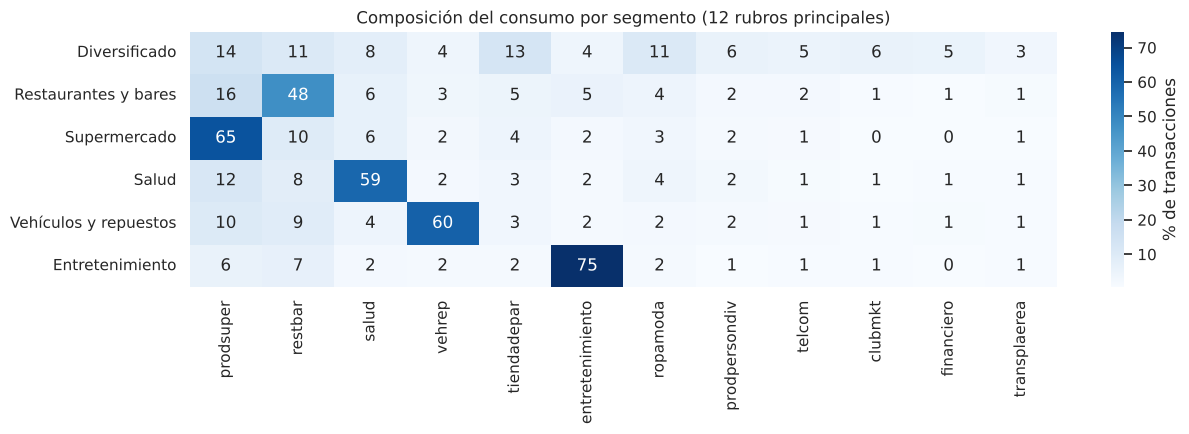

In [13]:
cols = perfil_global.index[:12]
tabla = (perfil.rename(index=nombre).loc[orden, cols] * 100)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de transacciones"}, ax=ax)
ax.set(title="Composición del consumo por segmento (12 rubros principales)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

In [14]:
top = []
for s in perfil.index:
    p = perfil.loc[s].sort_values(ascending=False)
    i = indice.loc[s].sort_values(ascending=False)
    top.append({
        "segmento": nombre[s],
        "rubro principal": f"{p.index[0]} ({p.iloc[0]:.0%})",
        "segundo rubro": f"{p.index[1]} ({p.iloc[1]:.0%})",
        "rubros sobrerrepresentados (índice)": ", ".join(f"{r} x{v:.1f}" for r, v in i.head(3).items()),
    })
pd.DataFrame(top).set_index("segmento").loc[orden]

,rubro principal,segundo rubro,rubros sobrerrepresentados (índice)
segmento,,,
Diversificado,prodsuper (14%),tiendadepar (13%),"clubmkt x2.5, financiero x2.4, artcultura x2.0"
Restaurantes y bares,restbar (48%),prodsuper (16%),"restbar x2.6, alqbienes x1.4, prodlocal x1.2"
Supermercado,prodsuper (65%),restbar (10%),"prodsuper x2.6, prodelectro x0.7, tiendadepar ..."
Salud,salud (59%),prodsuper (12%),"salud x5.2, hogaroficina x0.8, belleza x0.8"
Vehículos y repuestos,vehrep (60%),prodsuper (10%),"vehrep x8.0, hogaroficina x1.1, profdiverso x0.6"
Entretenimiento,entretenimiento (75%),restbar (7%),"entretenimiento x10.9, alqbienes x0.5, transpl..."


### 5.1 Actividad y perfil demográfico

In [15]:
actividad = base.assign(segmento=segmento.map(nombre))
actividad["trx_por_mes"] = actividad["trx_total"] / actividad["meses_activos"]
actividad["ticket_promedio"] = actividad["monto_total"] / actividad["trx_total"]

act = actividad.groupby("segmento").agg(
    meses_activos=("meses_activos", "median"),
    trx_por_mes=("trx_por_mes", "median"),
    ticket_promedio=("ticket_promedio", "median"),
).loc[orden].round(1)
act.columns = ["meses activos (mediana)", "transacciones/mes (mediana)", "ticket promedio (mediana)"]
act

,meses activos (mediana),transacciones/mes (mediana),ticket promedio (mediana)
segmento,,,
Diversificado,6.0,2.3,106.5
Restaurantes y bares,5.0,2.6,51.4
Supermercado,6.0,2.3,39.1
Salud,6.0,2.1,66.6
Vehículos y repuestos,6.0,2.5,54.7
Entretenimiento,5.0,2.8,70.1


In [16]:
demo = (df[df["cliente"].isin(base.index)]
        .drop_duplicates("cliente").set_index("cliente")[["edad", "ingreso", "sexo", "flgLimaProv"]])
demo["segmento"] = segmento.map(nombre)

def distribucion(var):
    t = pd.crosstab(demo["segmento"], demo[var], normalize="index") * 100
    return t.loc[orden].round(0)

print("Edad (% de clientes del segmento, sin nulos)")
display(distribucion("edad"))
print("Ingreso (% de clientes del segmento, sin nulos)")
display(distribucion("ingreso"))
print("Sexo y ubicación (% del segmento). La codificación de flgLimaProv (0/1) no está documentada en la fuente.")
display(pd.concat([distribucion("sexo"), distribucion("flgLimaProv").add_prefix("flgLimaProv=")], axis=1))

Edad (% de clientes del segmento, sin nulos)


edad,[1. <=25],[2. <=30],[3. <=35],[4. <=40],[5. <=45],[6. <=55],[7. > 55]
segmento,,,,,,,
Diversificado,11.0,16.0,15.0,14.0,12.0,17.0,15.0
Restaurantes y bares,20.0,23.0,17.0,13.0,9.0,10.0,7.0
Supermercado,16.0,18.0,16.0,13.0,11.0,13.0,12.0
Salud,9.0,15.0,16.0,16.0,12.0,15.0,18.0
Vehículos y repuestos,8.0,14.0,15.0,17.0,14.0,17.0,14.0
Entretenimiento,11.0,17.0,15.0,13.0,12.0,15.0,16.0


Ingreso (% de clientes del segmento, sin nulos)


ingreso,[1. <=700],[2. <=1500],[3. <=2500],[4. <=3500],[5. <=4500],[6. <=6000],[7. <=8000],[8. > 8000]
segmento,,,,,,,,
Diversificado,1.0,21.0,42.0,18.0,7.0,4.0,3.0,3.0
Restaurantes y bares,2.0,33.0,41.0,13.0,5.0,3.0,2.0,2.0
Supermercado,1.0,41.0,41.0,10.0,3.0,2.0,1.0,1.0
Salud,1.0,25.0,43.0,16.0,6.0,3.0,3.0,2.0
Vehículos y repuestos,1.0,27.0,42.0,16.0,6.0,3.0,2.0,2.0
Entretenimiento,0.0,34.0,46.0,12.0,4.0,2.0,1.0,1.0


Sexo y ubicación (% del segmento). La codificación de flgLimaProv (0/1) no está documentada en la fuente.


,F,M,flgLimaProv=0.0,flgLimaProv=1.0
segmento,,,,
Diversificado,47.0,53.0,30.0,70.0
Restaurantes y bares,43.0,57.0,18.0,82.0
Supermercado,46.0,54.0,22.0,78.0
Salud,55.0,45.0,32.0,68.0
Vehículos y repuestos,18.0,82.0,25.0,75.0
Entretenimiento,29.0,71.0,29.0,71.0


### 5.2 Vista en dos dimensiones

El PCA se usa **solo para visualizar** los segmentos en un plano. El modelo se entrenó sobre las 21 proporciones originales.

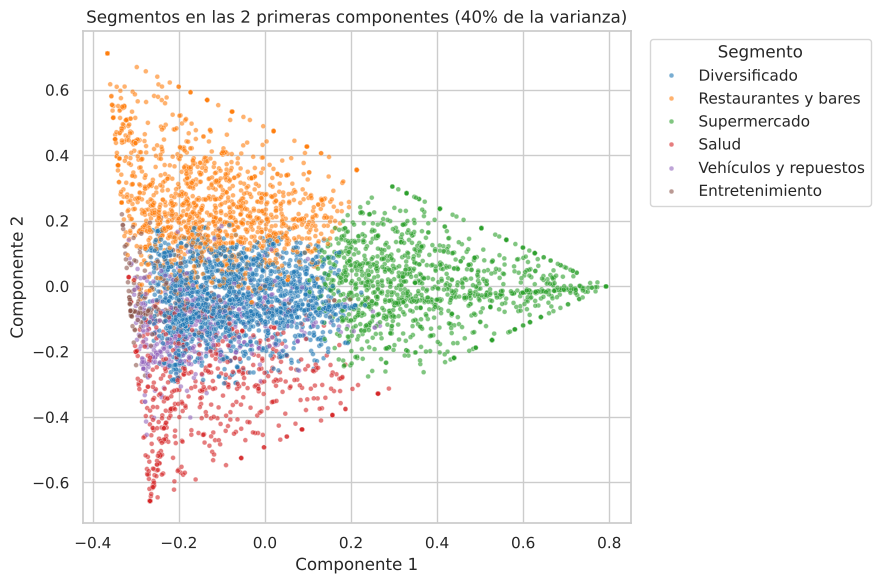

In [17]:
pca = PCA(n_components=2, random_state=SEMILLA)
coords = pca.fit_transform(X)
muestra = np.random.RandomState(SEMILLA).choice(len(X), 6000, replace=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=coords[muestra, 0], y=coords[muestra, 1], hue=segmento.map(nombre).iloc[muestra],
                hue_order=orden, palette="tab10", s=12, alpha=0.6, ax=ax)
ax.set(title=f"Segmentos en las 2 primeras componentes ({pca.explained_variance_ratio_.sum():.0%} de la varianza)",
       xlabel="Componente 1", ylabel="Componente 2")
ax.legend(title="Segmento", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 6. Recomendaciones de negocio

| Segmento | % clientes | Rasgos que lo distinguen | Oferta sugerida |
|---|---|---|---|
| Diversificado | 33% | Consumo repartido; ticket mediano más alto (106) y mayor proporción de ingresos sobre 2,500 | Programa de puntos multirrubro y beneficios en tiendas por departamento |
| Restaurantes y bares | 23% | 48% de sus transacciones en restaurantes; el más joven (43% hasta 30 años) | Descuentos en restaurantes y delivery |
| Supermercado | 22% | 65% en supermercados; ticket más bajo (39) y 42% con ingresos hasta 1,500 | Cashback en supermercados |
| Salud | 9% | 59% en salud; mayor proporción de mujeres (55%) y de mayores de 55 años | Alianzas con farmacias y clínicas |
| Vehículos y repuestos | 8% | 60% en vehículos y repuestos; 82% hombres | Descuentos en repuestos y servicios vehiculares |
| Entretenimiento | 5% | 75% en entretenimiento; la mayor frecuencia (2.8 transacciones/mes) | Preventas y descuentos en entretenimiento |
| Ocasionales (no segmentados) | 18,083 clientes | 1–2 meses con consumo en el año | Campañas de activación y uso de la tarjeta |

Las ofertas son hipótesis a validar: el siguiente paso es un piloto por segmento con grupo de control, para medir si la oferta dirigida supera a la oferta genérica.

## 7. Limitaciones

- **Fronteras difusas:** la silueta (~0.25) indica que muchos clientes están cerca de dos segmentos. Para campañas sensibles conviene usar la distancia al centroide y priorizar a los clientes más típicos de cada grupo.
- **Solo frecuencia, no monto:** los segmentos se forman con el número de transacciones. Un análisis complementario con el monto por rubro podría distinguir clientes de alto valor dentro de cada segmento.
- **Un año de historia (nov. 2016 – oct. 2017):** no permite ver estacionalidad entre años ni cambios de preferencia en el tiempo.
- **Sin respuesta a campañas:** los segmentos describen comportamiento, pero no prueban qué oferta funciona. El siguiente paso natural es un piloto con grupo de control por segmento.
- **Demográficas en rangos y con nulos:** sirven para describir los segmentos, no para predecirlos.